In [3]:
import quarters_clean

In [4]:
cpi_q_df = quarters_clean.pd.read_parquet("../data/quarter_cpi_values.parquet")
cpi_q_df.tail()

,Australia,New-Zealand,Year,Month,Quarter
257,117.2,1059.0,2020,None,4
258,121.3,1122.0,2021,None,4
259,130.8,1203.0,2022,None,4
260,136.1,1259.0,2023,None,4
261,139.4,1287.0,2024,None,4


In [5]:
cpi_q_df.head()

,Australia,New-Zealand,Year,Month,Quarter
0,7.5,44.8764,1960,None,1
1,7.8,45.5819,1961,None,1
2,7.8,46.9145,1962,None,1
3,7.8,47.7767,1963,None,1
4,8.0,48.9917,1964,None,1


In [6]:
quarters_clean.summarize_missing_by_country(cpi_q_df)

,Missing Count,Missing %
Month,262,100.0
Australia,0,0.0
New-Zealand,0,0.0


In [7]:
cpi_q_df = cpi_q_df.drop(columns=["Month"])

In [8]:
quarters_clean.summarize_missing_by_country(cpi_q_df)

,Missing Count,Missing %
Australia,0,0.0
New-Zealand,0,0.0


In [9]:
cpi_q_df = cpi_q_df.sort_values(by=['Year', 'Quarter'])
cpi_q_df

,Australia,New-Zealand,Year,Quarter
0,7.5,44.8764,1960,1
66,7.6,44.9548,1960,2
132,7.7,45.3467,1960,3
197,7.8,45.7779,1960,4
1,7.8,45.5819,1961,1
...,...,...,...,...
130,138.8,1272.0000,2024,2
196,139.1,1280.0000,2024,3
261,139.4,1287.0000,2024,4
65,140.7,1299.0000,2025,1


In [10]:
cpi_q_df = cpi_q_df.reset_index(drop=True)
cpi_q_df

,Australia,New-Zealand,Year,Quarter
0,7.5,44.8764,1960,1
1,7.6,44.9548,1960,2
2,7.7,45.3467,1960,3
3,7.8,45.7779,1960,4
4,7.8,45.5819,1961,1
...,...,...,...,...
257,138.8,1272.0000,2024,2
258,139.1,1280.0000,2024,3
259,139.4,1287.0000,2024,4
260,140.7,1299.0000,2025,1


In [11]:
cpi_q_df = quarters_clean.average_by_year(cpi_q_df)
cpi_q_df

   Year  Australia  New-Zealand
0  1960      7.650    45.238950
1  1961      7.825    46.052225
2  1962      7.800    47.286800
3  1963      7.850    48.217625
4  1964      8.075    49.893150


,Year,Australia,New-Zealand
0,1960,7.650,45.238950
1,1961,7.825,46.052225
2,1962,7.800,47.286800
3,1963,7.850,48.217625
4,1964,8.075,49.893150
...,...,...,...
61,2021,119.425,1094.500000
62,2022,127.300,1173.000000
63,2023,134.425,1240.250000
64,2024,138.675,1276.500000


In [12]:
cpi_m_df = quarters_clean.pd.read_parquet("../data/month_cpi_values.parquet")
cpi_m_df.tail()

,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
782,108.67,108.21,5391.75,105.70,136.9,79.72,127.9984,105.29,103.18,99.70,...,108.06,100.44,102.18,182.90,260.280,109.1,106.6,2020,Sep,3
783,112.23,112.35,5944.21,109.92,142.9,83.98,128.4814,110.04,106.80,103.31,...,111.29,101.29,101.21,218.71,274.310,112.4,113.4,2021,Sep,3
784,124.58,125.90,6370.34,127.10,152.7,95.51,131.9948,122.63,120.21,112.63,...,122.70,104.53,107.70,401.10,296.808,122.3,124.0,2022,Sep,3
785,131.75,126.73,6700.66,135.18,158.5,100.39,132.1184,136.11,129.15,117.48,...,127.19,106.57,108.02,648.45,307.789,130.1,128.3,2023,Sep,3
786,134.13,132.21,6997.15,137.25,161.1,104.54,132.7618,144.02,133.11,119.41,...,128.76,107.50,108.68,969.11,315.301,133.5,133.5,2024,Sep,3


In [13]:
quarters_clean.summarize_missing_by_country(cpi_m_df)

,Missing Count,Missing %
Peru,624,79.29
India,612,77.76
Morocco,565,71.79
South-Africa,565,71.79
Serbia,551,70.01
Switzerland,539,68.49
Macedonia,539,68.49
Russia,500,63.53
Croatia,456,57.94
Indonesia,451,57.31


**H1)** The previous output indicates that Peru will be the country that will most restrict us in the time range available to perform the correlation analysis. This statement is only correct due to the process of extracting and joining the values of this indicator. If indicators were downloaded for a country and those values were not available for a time range already existing in the master data frame, NaN values were assigned.

In [15]:
missing_entries = quarters_clean.get_missing_entries(cpi_m_df)
missing_entries.head()

,Quarter,Year,Country,Value
0,1,1960,Austria,NaN
1,1,1960,Austria,NaN
2,1,1960,Austria,NaN
3,1,1960,Belgium,NaN
4,1,1960,Belgium,NaN


In [16]:
peru_missing = quarters_clean.clean_country_missing_entries(missing_entries, "Peru")
peru_missing

,Quarter,Year,Country,Value
0,1,1960,Peru,NaN
1,1,1960,Peru,NaN
2,1,1960,Peru,NaN
3,2,1960,Peru,NaN
4,2,1960,Peru,NaN
...,...,...,...,...
619,3,2011,Peru,NaN
620,3,2011,Peru,NaN
621,4,2011,Peru,NaN
622,4,2011,Peru,NaN


The previous outputs show us that Peru has no values for the investment index from 1960 to 2011. Consequently, it has values in the range from 2012 to 2024, a desirable range since other values which we extracted with the crawlers are defined between 2014 and 2023.

### Let's delete all the data from the beginning until 2011

In [17]:
clean_df1 = cpi_m_df.copy()

In [19]:
clean_df1 = quarters_clean.filter_by_year(clean_df1, min_year=2011, max_year=2024)
clean_df1

,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
0,95.82,97.80,3467.46,101.94,121.7,62.06,108.3481,77.42,97.28,101.95,...,98.99,101.30,96.35,79.45,230.085,96.0,81.6892,2012,Apr,2
1,97.82,98.98,3692.62,102.90,122.9,62.68,110.9716,78.99,100.29,102.02,...,99.03,100.90,98.68,84.23,232.531,98.3,82.9787,2013,Apr,2
2,99.35,99.74,3924.50,101.54,124.8,65.82,112.8535,81.14,100.21,101.61,...,99.31,101.00,101.10,92.12,237.072,100.1,88.2656,2014,Apr,2
3,100.28,100.11,4245.19,100.66,126.3,68.54,114.5774,84.90,100.11,99.85,...,99.82,100.12,100.05,99.43,236.600,99.9,90.0709,2015,Apr,2
4,100.93,101.65,4639.05,98.12,127.9,71.42,117.2206,91.63,99.23,97.74,...,100.86,99.59,100.11,105.99,239.260,100.2,94.1328,2016,Apr,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,108.67,108.21,5391.75,105.70,136.9,79.72,127.9984,105.29,103.18,99.70,...,108.06,100.44,102.18,182.90,260.280,109.1,106.6000,2020,Sep,3
152,112.23,112.35,5944.21,109.92,142.9,83.98,128.4814,110.04,106.80,103.31,...,111.29,101.29,101.21,218.71,274.310,112.4,113.4000,2021,Sep,3
153,124.58,125.90,6370.34,127.10,152.7,95.51,131.9948,122.63,120.21,112.63,...,122.70,104.53,107.70,401.10,296.808,122.3,124.0000,2022,Sep,3
154,131.75,126.73,6700.66,135.18,158.5,100.39,132.1184,136.11,129.15,117.48,...,127.19,106.57,108.02,648.45,307.789,130.1,128.3000,2023,Sep,3


In [20]:
clean_df1 = clean_df1.sort_values(by=['Year', 'Quarter'])
clean_df1

,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
39,94.38,97.65,3438.19,101.56,120.7,61.93,108.2479,77.22,95.19,99.05,...,98.29,100.40,95.38,77.89,227.663,95.1,81.4958,2012,Feb,1
52,93.88,95.34,3422.79,100.96,120.2,61.69,108.3481,76.75,94.60,98.63,...,97.57,100.20,95.03,77.42,226.665,94.6,80.2708,2012,Jan,1
91,95.55,97.75,3445.41,101.70,121.2,62.03,108.4482,77.31,96.47,100.47,...,98.73,101.20,95.95,78.20,229.392,95.4,81.8827,2012,Mar,1
0,95.82,97.80,3467.46,101.94,121.7,62.06,108.3481,77.42,97.28,101.95,...,98.99,101.30,96.35,79.45,230.085,96.0,81.6892,2012,Apr,2
78,95.62,97.59,3482.72,101.30,122.1,61.90,107.4468,77.72,98.29,102.58,...,98.64,100.80,96.89,78.56,229.478,95.5,81.6892,2012,June,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77,133.95,130.76,6967.89,138.75,162.1,104.19,132.2329,143.67,133.69,118.76,...,129.11,107.89,108.71,918.24,314.540,132.9,133.5000,2024,Jul,3
155,134.13,132.21,6997.15,137.25,161.1,104.54,132.7618,144.02,133.11,119.41,...,128.76,107.50,108.68,969.11,315.301,133.5,133.5000,2024,Sep,3
38,135.92,134.12,7100.50,138.99,161.2,105.62,131.5694,144.88,134.35,117.65,...,130.46,106.86,NaN,1029.82,315.605,135.1,134.7000,2024,Dec,4
129,135.00,133.13,7063.77,138.53,161.8,105.83,131.5694,144.22,134.10,118.02,...,130.11,106.92,NaN,1019.26,315.493,134.6,133.8000,2024,Nov,4


In [21]:
quarters_clean.summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
Indonesia,12,7.69
Thailand,4,2.56
Russia,1,0.64
Belgium,0,0.00
Brazil,0,0.00
Chile,0,0.00
China,0,0.00
Bulgaria,0,0.00
Canada,0,0.00
Croatia,0,0.00


In [22]:
clean_df1["Russia"] = clean_df1["Russia"].ffill()

In [24]:
missing_entries = quarters_clean.get_missing_entries(clean_df1)
missing_entries

,Quarter,Year,Country,Value
0,1,2024,Indonesia,NaN
1,1,2024,Indonesia,NaN
2,1,2024,Indonesia,NaN
3,2,2024,Indonesia,NaN
4,2,2024,Indonesia,NaN
5,2,2024,Indonesia,NaN
6,3,2024,Indonesia,NaN
7,3,2024,Indonesia,NaN
8,3,2024,Indonesia,NaN
9,3,2024,Thailand,NaN


In [25]:
clean_df1["Indonesia"] = clean_df1["Indonesia"].ffill()

In [26]:
clean_df1["Thailand"] = clean_df1["Thailand"].ffill()

In [27]:
quarters_clean.summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
Austria,0,0.0
Belgium,0,0.0
Brazil,0,0.0
Bulgaria,0,0.0
Canada,0,0.0
Chile,0,0.0
China,0,0.0
Colombia,0,0.0
Croatia,0,0.0
Cyprus,0,0.0


In [29]:
clean_df1 = clean_df1.reset_index(drop=True)
clean_df1

,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
0,94.38,97.65,3438.19,101.56,120.7,61.93,108.2479,77.22,95.19,99.05,...,98.29,100.40,95.38,77.89,227.663,95.1,81.4958,2012,Feb,1
1,93.88,95.34,3422.79,100.96,120.2,61.69,108.3481,76.75,94.60,98.63,...,97.57,100.20,95.03,77.42,226.665,94.6,80.2708,2012,Jan,1
2,95.55,97.75,3445.41,101.70,121.2,62.03,108.4482,77.31,96.47,100.47,...,98.73,101.20,95.95,78.20,229.392,95.4,81.8827,2012,Mar,1
3,95.82,97.80,3467.46,101.94,121.7,62.06,108.3481,77.42,97.28,101.95,...,98.99,101.30,96.35,79.45,230.085,96.0,81.6892,2012,Apr,2
4,95.62,97.59,3482.72,101.30,122.1,61.90,107.4468,77.72,98.29,102.58,...,98.64,100.80,96.89,78.56,229.478,95.5,81.6892,2012,June,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,133.95,130.76,6967.89,138.75,162.1,104.19,132.2329,143.67,133.69,118.76,...,129.11,107.89,108.71,918.24,314.540,132.9,133.5000,2024,Jul,3
152,134.13,132.21,6997.15,137.25,161.1,104.54,132.7618,144.02,133.11,119.41,...,128.76,107.50,108.68,969.11,315.301,133.5,133.5000,2024,Sep,3
153,135.92,134.12,7100.50,138.99,161.2,105.62,131.5694,144.88,134.35,117.65,...,130.46,106.86,108.68,1029.82,315.605,135.1,134.7000,2024,Dec,4
154,135.00,133.13,7063.77,138.53,161.8,105.83,131.5694,144.22,134.10,118.02,...,130.11,106.92,108.68,1019.26,315.493,134.6,133.8000,2024,Nov,4


In [30]:
clean_df2 = clean_df1.copy()

In [31]:
clean_df2 = quarters_clean.average_by_year(clean_df2)

   Year     Austria     Belgium       Brazil    Bulgaria      Canada  \
0  2012   95.745833   97.679167  3500.657500  102.326667  121.591667   
1  2013   97.773333   98.898333  3717.849167  102.720833  122.691667   
2  2014   99.201667   99.383333  3953.153333  101.076667  125.008333   
3  2015  100.000000   99.999167  4310.119167   99.998333  126.400000   
4  2016  100.970833  101.769167  4686.786667   98.675833  128.216667   

       Chile       China   Colombia     Croatia  ...  South-Africa  \
0  62.173333  108.318908  77.631667   97.763333  ...     78.425000   
1  63.290833  111.158000  79.198333  100.037500  ...     82.925000   
2  66.274167  113.294050  81.495833  100.257500  ...     87.975000   
3  69.157500  114.922117  85.560000  100.000833  ...     92.000000   
4  71.775000  117.220575  91.988333   99.370833  ...     97.833333   

   South-Korea       Spain      Sweden  Switzerland    Thailand      Turkey  \
0    91.815083   99.305833   98.663333   100.758333   96.912500   7

In [32]:
clean_df2

,Year,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
0,2012,95.745833,97.679167,3500.657500,102.326667,121.591667,62.173333,108.318908,77.631667,97.763333,...,78.425000,91.815083,99.305833,98.663333,100.758333,96.912500,79.306667,229.593917,96.041667,81.678483
1,2013,97.773333,98.898333,3717.849167,102.720833,122.691667,63.290833,111.158000,79.198333,100.037500,...,82.925000,93.009917,100.825000,99.098333,100.833333,99.030000,85.217500,232.957083,98.508333,83.870625
2,2014,99.201667,99.383333,3953.153333,101.076667,125.008333,66.274167,113.294050,81.495833,100.257500,...,87.975000,94.195583,100.633333,99.302500,100.841667,100.907500,92.811667,236.736167,99.958333,88.088325
3,2015,100.000000,99.999167,4310.119167,99.998333,126.400000,69.157500,114.922117,85.560000,100.000833,...,92.000000,94.860917,100.000000,100.000000,100.000000,99.999167,100.000000,237.019167,100.008333,90.844608
4,2016,100.970833,101.769167,4686.786667,98.675833,128.216667,71.775000,117.220575,91.988333,99.370833,...,97.833333,95.782667,99.663333,101.135833,99.469167,100.187500,107.655833,240.011667,100.650000,94.557258
5,2017,103.223333,104.032500,4848.310833,99.848333,130.225000,73.340833,119.088050,95.958333,100.665000,...,102.991667,97.645000,101.692500,103.023333,100.106667,100.856667,119.625000,245.119667,103.358333,97.963675
6,2018,105.411667,106.436667,5025.994167,102.475833,133.383333,75.127500,121.558883,99.068333,102.232500,...,107.750000,99.086083,103.457500,105.120833,101.025000,101.930000,139.169167,251.106833,105.916667,101.858333
7,2019,106.983333,107.765833,5213.613333,104.994167,135.983333,77.048333,124.927017,102.555833,103.041667,...,112.200000,99.465583,104.264167,106.930000,101.409167,102.645000,160.298333,255.657417,107.800000,104.666667
8,2020,108.468333,108.226667,5381.062500,106.274167,136.958333,79.397500,127.859475,105.145833,103.060833,...,115.866667,100.000000,103.912500,107.632500,100.555833,101.559167,179.980000,258.811167,108.783333,106.516667
9,2021,111.460833,111.714167,5827.780000,109.295000,141.608333,82.987500,128.931925,108.821667,105.816667,...,121.133333,102.498333,107.038333,110.486667,101.035000,100.367500,215.239167,270.969750,111.608333,111.616667


In [33]:
cpi_q_df

,Year,Australia,New-Zealand
0,1960,7.650,45.238950
1,1961,7.825,46.052225
2,1962,7.800,47.286800
3,1963,7.850,48.217625
4,1964,8.075,49.893150
...,...,...,...
61,2021,119.425,1094.500000
62,2022,127.300,1173.000000
63,2023,134.425,1240.250000
64,2024,138.675,1276.500000


In [34]:
clean_df3 = quarters_clean.filter_by_year(cpi_q_df, min_year=2011, max_year=2024)
clean_df3

,Year,Australia,New-Zealand
0,2012,101.025,952.691675
1,2013,103.500,963.499175
2,2014,106.075,975.326250
3,2015,107.675,978.181075
4,2016,109.050,984.502450
5,2017,111.175,1002.723500
6,2018,113.300,1018.750000
7,2019,115.125,1035.250000
8,2020,116.100,1053.000000
9,2021,119.425,1094.500000


In [36]:
df_merged = quarters_clean.pd.merge(clean_df2, clean_df3, on='Year')
df_merged

,Year,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Australia,New-Zealand
0,2012,95.745833,97.679167,3500.657500,102.326667,121.591667,62.173333,108.318908,77.631667,97.763333,...,99.305833,98.663333,100.758333,96.912500,79.306667,229.593917,96.041667,81.678483,101.025,952.691675
1,2013,97.773333,98.898333,3717.849167,102.720833,122.691667,63.290833,111.158000,79.198333,100.037500,...,100.825000,99.098333,100.833333,99.030000,85.217500,232.957083,98.508333,83.870625,103.500,963.499175
2,2014,99.201667,99.383333,3953.153333,101.076667,125.008333,66.274167,113.294050,81.495833,100.257500,...,100.633333,99.302500,100.841667,100.907500,92.811667,236.736167,99.958333,88.088325,106.075,975.326250
3,2015,100.000000,99.999167,4310.119167,99.998333,126.400000,69.157500,114.922117,85.560000,100.000833,...,100.000000,100.000000,100.000000,99.999167,100.000000,237.019167,100.008333,90.844608,107.675,978.181075
4,2016,100.970833,101.769167,4686.786667,98.675833,128.216667,71.775000,117.220575,91.988333,99.370833,...,99.663333,101.135833,99.469167,100.187500,107.655833,240.011667,100.650000,94.557258,109.050,984.502450
5,2017,103.223333,104.032500,4848.310833,99.848333,130.225000,73.340833,119.088050,95.958333,100.665000,...,101.692500,103.023333,100.106667,100.856667,119.625000,245.119667,103.358333,97.963675,111.175,1002.723500
6,2018,105.411667,106.436667,5025.994167,102.475833,133.383333,75.127500,121.558883,99.068333,102.232500,...,103.457500,105.120833,101.025000,101.930000,139.169167,251.106833,105.916667,101.858333,113.300,1018.750000
7,2019,106.983333,107.765833,5213.613333,104.994167,135.983333,77.048333,124.927017,102.555833,103.041667,...,104.264167,106.930000,101.409167,102.645000,160.298333,255.657417,107.800000,104.666667,115.125,1035.250000
8,2020,108.468333,108.226667,5381.062500,106.274167,136.958333,79.397500,127.859475,105.145833,103.060833,...,103.912500,107.632500,100.555833,101.559167,179.980000,258.811167,108.783333,106.516667,116.100,1053.000000
9,2021,111.460833,111.714167,5827.780000,109.295000,141.608333,82.987500,128.931925,108.821667,105.816667,...,107.038333,110.486667,101.035000,100.367500,215.239167,270.969750,111.608333,111.616667,119.425,1094.500000


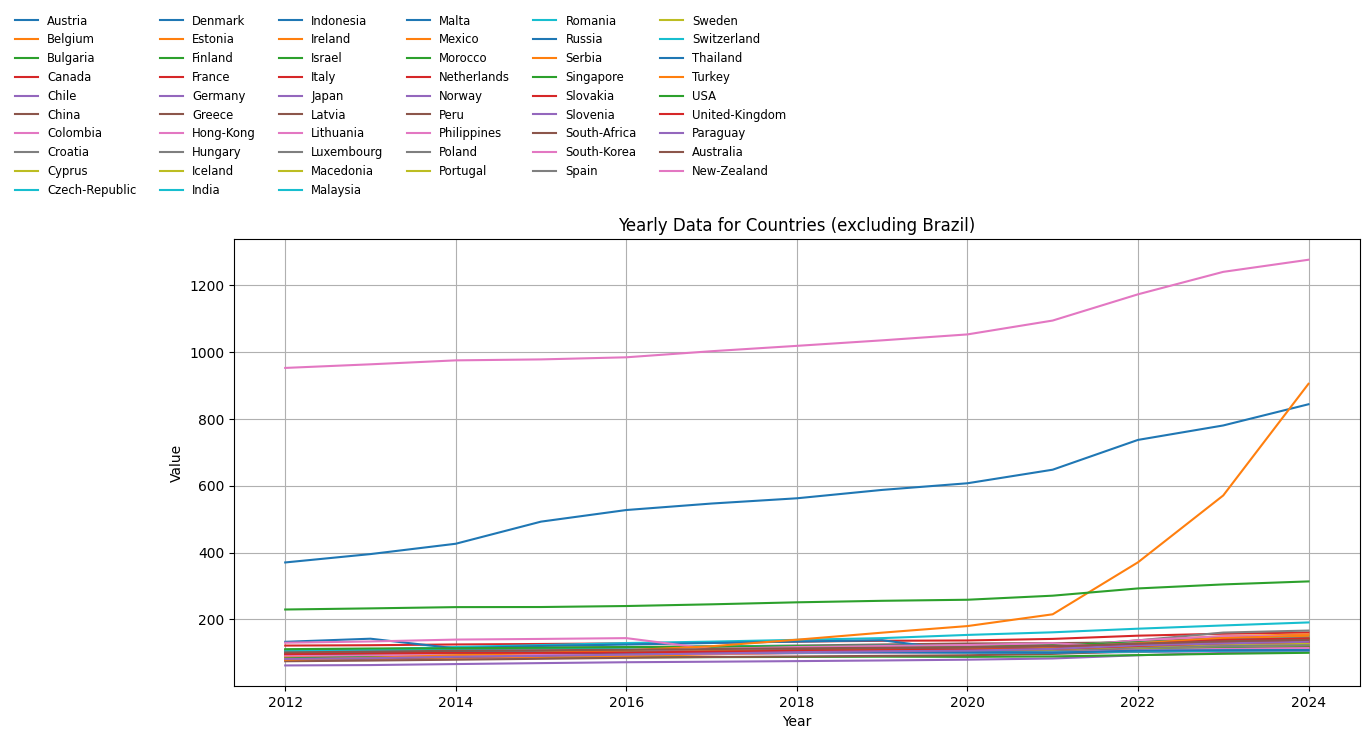

In [38]:
quarters_clean.plot_countries(df_merged, exclude_country='Brazil', legend_columns=6)

In [39]:
df_merged

,Year,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Australia,New-Zealand
0,2012,95.745833,97.679167,3500.657500,102.326667,121.591667,62.173333,108.318908,77.631667,97.763333,...,99.305833,98.663333,100.758333,96.912500,79.306667,229.593917,96.041667,81.678483,101.025,952.691675
1,2013,97.773333,98.898333,3717.849167,102.720833,122.691667,63.290833,111.158000,79.198333,100.037500,...,100.825000,99.098333,100.833333,99.030000,85.217500,232.957083,98.508333,83.870625,103.500,963.499175
2,2014,99.201667,99.383333,3953.153333,101.076667,125.008333,66.274167,113.294050,81.495833,100.257500,...,100.633333,99.302500,100.841667,100.907500,92.811667,236.736167,99.958333,88.088325,106.075,975.326250
3,2015,100.000000,99.999167,4310.119167,99.998333,126.400000,69.157500,114.922117,85.560000,100.000833,...,100.000000,100.000000,100.000000,99.999167,100.000000,237.019167,100.008333,90.844608,107.675,978.181075
4,2016,100.970833,101.769167,4686.786667,98.675833,128.216667,71.775000,117.220575,91.988333,99.370833,...,99.663333,101.135833,99.469167,100.187500,107.655833,240.011667,100.650000,94.557258,109.050,984.502450
5,2017,103.223333,104.032500,4848.310833,99.848333,130.225000,73.340833,119.088050,95.958333,100.665000,...,101.692500,103.023333,100.106667,100.856667,119.625000,245.119667,103.358333,97.963675,111.175,1002.723500
6,2018,105.411667,106.436667,5025.994167,102.475833,133.383333,75.127500,121.558883,99.068333,102.232500,...,103.457500,105.120833,101.025000,101.930000,139.169167,251.106833,105.916667,101.858333,113.300,1018.750000
7,2019,106.983333,107.765833,5213.613333,104.994167,135.983333,77.048333,124.927017,102.555833,103.041667,...,104.264167,106.930000,101.409167,102.645000,160.298333,255.657417,107.800000,104.666667,115.125,1035.250000
8,2020,108.468333,108.226667,5381.062500,106.274167,136.958333,79.397500,127.859475,105.145833,103.060833,...,103.912500,107.632500,100.555833,101.559167,179.980000,258.811167,108.783333,106.516667,116.100,1053.000000
9,2021,111.460833,111.714167,5827.780000,109.295000,141.608333,82.987500,128.931925,108.821667,105.816667,...,107.038333,110.486667,101.035000,100.367500,215.239167,270.969750,111.608333,111.616667,119.425,1094.500000


In [40]:
df_merged.to_parquet("../data/clean_cpi_index.parquet", index=False)